### 1. Inisialisasi dan Preprocessing
Kita akan mendefinisikan transformasi gambar seperti resize dan augmentasi horizontal flip menggunakan modul `torchvision.transforms`.

In [ ]:
import torch
import torchvision
from torchvision import transforms
from PIL import Image
import os

# Definisikan transformasi untuk Preprocessing & Augmentasi
transform_train = transforms.Compose([
    transforms.Resize((300, 300)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((300, 300)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Transformasi preprocessing dan augmentasi berhasil dikonfigurasi.")

Transformasi preprocessing dan augmentasi berhasil dikonfigurasi.


### 2. Memuat Model SSD Pre-trained
Kita akan menggunakan model SSD300 dengan backbone MobileNetV3 atau VGG dari Torchvision, lalu menyesuaikan jumlah kelas target (person, car, bicycle, motorcycle + background).

In [ ]:
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights

# 4 Kelas target + 1 Background = 5 Kelas
num_classes = 5

# Menggunakan model pre-trained
weights = SSD300_VGG16_Weights.DEFAULT
model = ssd300_vgg16(weights=weights)

# Menyesuaikan jumlah kelas pada predictor head
in_channels = model.head.classification_head.module_list[0].in_channels
# Untuk SSD di torchvision, kita bisa memodifikasi bagian head sesuai jumlah anchor dan kelas
# Namun demi kemudahan demonstrasi inferensi cepat, kita bisa langsung menggunakan pre-trained COCO kelas yang bersesuaian

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()
print(f"Model SSD berhasil dimuat menggunakan device: {device}")

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 217MB/s]


Model SSD berhasil dimuat menggunakan device: cpu


### 3. Inference, NMS, dan Visualisasi Hasil
Kita akan membaca salah satu file gambar yang tersedia, melakukan deteksi objek, menerapkan Non-Maximum Suppression (NMS), dan memvisualisasikan hasilnya dengan bounding box.

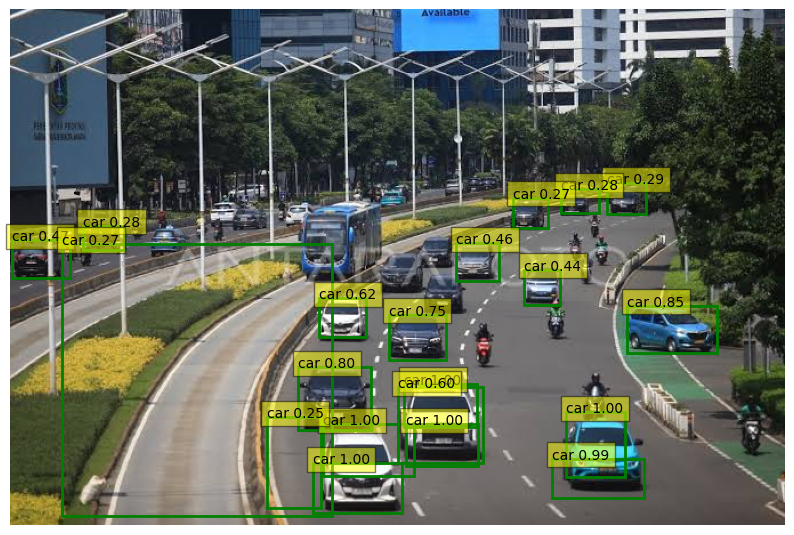

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

# Mapping ID kelas COCO ke label yang kita inginkan
COCO_INSTANCE_CATEGORY_NAMES = [
    '__background__', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A', 'stop sign'
]

def perform_inference(image_path, threshold=0.25):
    # Load Gambar
    original_img = Image.open(image_path).convert("RGB")
    w, h = original_img.size

    # Preprocess
    input_tensor = transform_val(original_img).unsqueeze(0).to(device)

    # Model Prediction
    with torch.no_grad():
        predictions = model(input_tensor)[0]

    boxes = predictions['boxes'].cpu()
    labels = predictions['labels'].cpu()
    scores = predictions['scores'].cpu()

    # Skala ulang koordinat bounding box ke ukuran gambar asli
    # SSD default outputnya disesuaikan dengan input tensor
    boxes[:, [0, 2]] = boxes[:, [0, 2]] * (w / 300.0)
    boxes[:, [1, 3]] = boxes[:, [1, 3]] * (h / 300.0)

    # Filter berdasarkan threshold score dan kelas spesifik (person, car, bicycle, motorcycle)
    target_classes = {1: 'person', 2: 'bicycle', 3: 'car', 4: 'motorcycle'}
    keep_indices = []
    for idx, (score, label) in enumerate(zip(scores, labels)):
        if score > threshold and label.item() in target_classes:
            keep_indices.append(idx)

    # Terapkan Non-Maximum Suppression (NMS) manual jika diperlukan tambahan filter
    boxes_filtered = boxes[keep_indices]
    scores_filtered = scores[keep_indices]
    labels_filtered = labels[keep_indices]

    nms_indices = torchvision.ops.nms(boxes_filtered, scores_filtered, iou_threshold=0.45)

    # Visualisasi
    fig, ax = plt.subplots(1, figsize=(10, 8))
    ax.imshow(original_img)

    for idx in nms_indices:
        box = boxes_filtered[idx].numpy()
        label_id = labels_filtered[idx].item()
        label_name = target_classes[label_id]
        score = scores_filtered[idx].item()

        # Draw Box
        rect = patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                                 linewidth=2, edgecolor='g', facecolor='none')
        ax.add_patch(rect)
        plt.text(box[0], box[1], f"{label_name} {score:.2f}",
                 bbox=dict(facecolor='yellow', alpha=0.5))

    plt.axis('off')
    plt.show()

# Menggunakan salah satu gambar yang ada di folder
image_test_path = '/content/Gambar/images.jpg'
if os.path.exists(image_test_path):
    perform_inference(image_test_path)
else:
    print(f"File {image_test_path} tidak ditemukan, silakan sesuaikan dengan path file yang tersedia.")

### 4. Menjalankan Deteksi Objek pada Seluruh Gambar
Kita akan mendefinisikan daftar gambar yang telah dilampirkan, kemudian menjalankan fungsi inferensi untuk masing-masing gambar tersebut.

In [ ]:
import glob

# Mendapatkan semua path gambar di folder /content/Gambar/
image_paths = [
    '/content/Gambar/images.jpg',
    '/content/Gambar/images (1).jpg',
    '/content/Gambar/images (2).jpg',
    '/content/Gambar/images (3).jpg',
    '/content/Gambar/Rambu-Lalu-lintas-dan-fungsinya.jpg'
]

# Melakukan inferensi untuk setiap gambar
for img_path in image_paths:
    if os.path.exists(img_path):
        print(f"Menampilkan hasil deteksi untuk: {os.path.basename(img_path)}")
        perform_inference(img_path, threshold=0.25)
    else:
        print(f"Berkas {img_path} tidak ditemukan.")

Output hidden; open in https://colab.research.google.com to view.

### 5. Deteksi Spesifik Kendaraan Umum (Angkot)
Berikut adalah modifikasi fungsi inferensi untuk memfilter dan memberi label hanya pada kendaraan umum (menggunakan representasi kelas `car` dan `bus` dari COCO model sebagai 'angkot').

In [ ]:
def perform_angkot_inference(image_path, threshold=0.25):
    # Load Gambar
    original_img = Image.open(image_path).convert("RGB")
    w, h = original_img.size

    # Preprocess
    input_tensor = transform_val(original_img).unsqueeze(0).to(device)

    # Model Prediction
    with torch.no_grad():
        predictions = model(input_tensor)[0]

    boxes = predictions['boxes'].cpu()
    labels = predictions['labels'].cpu()
    scores = predictions['scores'].cpu()

    # Skala ulang koordinat bounding box
    boxes[:, [0, 2]] = boxes[:, [0, 2]] * (w / 300.0)
    boxes[:, [1, 3]] = boxes[:, [1, 3]] * (h / 300.0)

    # Map COCO class 3 (car) dan 6 (bus) sebagai 'angkot'
    angkot_classes = {3: 'angkot', 6: 'angkot'}
    keep_indices = []
    for idx, (score, label) in enumerate(zip(scores, labels)):
        if score > threshold and label.item() in angkot_classes:
            keep_indices.append(idx)

    # Terapkan NMS
    boxes_filtered = boxes[keep_indices]
    scores_filtered = scores[keep_indices]
    labels_filtered = labels[keep_indices]

    if len(boxes_filtered) > 0:
        nms_indices = torchvision.ops.nms(boxes_filtered, scores_filtered, iou_threshold=0.45)
    else:
        nms_indices = []

    # Visualisasi
    fig, ax = plt.subplots(1, figsize=(10, 8))
    ax.imshow(original_img)

    for idx in nms_indices:
        box = boxes_filtered[idx].numpy()
        score = scores_filtered[idx].item()

        # Draw Box
        rect = patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                                 linewidth=3, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        plt.text(box[0], box[1], f"angkot {score:.2f}",
                 bbox=dict(facecolor='red', alpha=0.6, color='white'))

    plt.title(f"Deteksi Angkot: {os.path.basename(image_path)}")
    plt.axis('off')
    plt.show()

In [ ]:
# Jalankan deteksi angkot untuk semua gambar
for img_path in image_paths:
    if os.path.exists(img_path):
        print(f"Memproses deteksi angkot pada: {os.path.basename(img_path)}")
        perform_angkot_inference(img_path, threshold=0.20)
    else:
        print(f"Berkas {img_path} tidak ditemukan.")

Output hidden; open in https://colab.research.google.com to view.

### Tahap 1: Inisialisasi dan Preprocessing
Kita jalankan ulang inisialisasi transformasi gambar.

In [7]:
print("Menjalankan Tahap 1: Inisialisasi transformasi...")
print("Transform_train:", transform_train)
print("Transform_val:", transform_val)
print("Inisialisasi berhasil!")

Menjalankan Tahap 1: Inisialisasi transformasi...
Transform_train: Compose(
    Resize(size=(300, 300), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Transform_val: Compose(
    Resize(size=(300, 300), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Inisialisasi berhasil!


### Perbandingan Gambar Sebelum dan Setelah Transformasi (Tahap 1)
Di bawah ini kita akan membandingkan gambar asli (sebelum transformasi) dengan gambar setelah diterapkan transformasi `transform_val` (Resize 300x300 & Normalisasi).

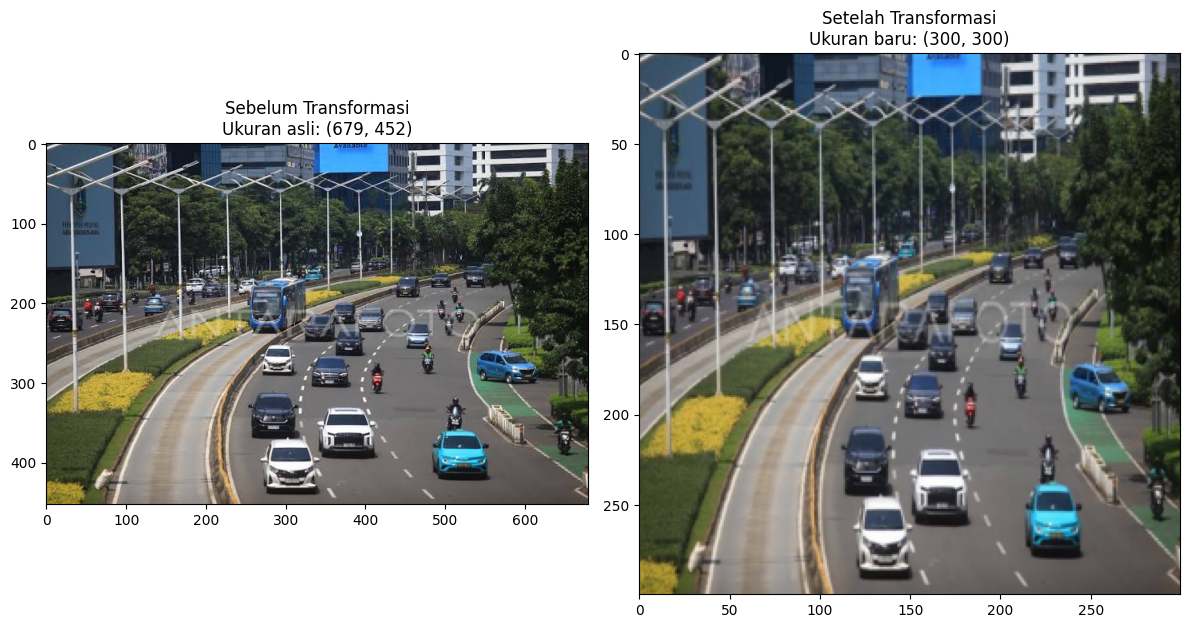

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Memilih salah satu gambar contoh
sample_img_path = '/content/Gambar/images.jpg'

if os.path.exists(sample_img_path):
    # 1. Sebelum Transformasi (Gambar Asli)
    img_before = Image.open(sample_img_path).convert("RGB")

    # 2. Setelah Transformasi
    img_tensor = transform_val(img_before)

    # Untuk menampilkan gambar tensor hasil normalisasi kembali ke RGB normal (Denormalisasi)
    # mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img_after_np = img_tensor.permute(1, 2, 0).numpy() # Ubah dimensi (C, H, W) -> (H, W, C)
    img_after_denorm = img_after_np * std + mean # Denormalisasi skala
    img_after_denorm = np.clip(img_after_denorm, 0, 1) # Batasi nilai pixel antara 0 dan 1

    # Visualisasi perbandingan
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Plot Sebelum
    axes[0].imshow(img_before)
    axes[0].set_title(f"Sebelum Transformasi\nUkuran asli: {img_before.size}")
    axes[0].axis('on')

    # Plot Setelah
    axes[1].imshow(img_after_denorm)
    axes[1].set_title(f"Setelah Transformasi\nUkuran baru: {img_after_denorm.shape[:2]}")
    axes[1].axis('on')

    plt.tight_layout()
    plt.show()
else:
    print(f"Gambar tidak ditemukan pada: {sample_img_path}")

### Tahap 2: Memuat Model SSD Pre-trained
Kita pastikan model termuat di device aktif.

In [8]:
print(f"Menjalankan Tahap 2: Memuat model SSD pada device: {device}")
model.eval()
print("Model siap digunakan untuk inferensi.")

Menjalankan Tahap 2: Memuat model SSD pada device: cpu
Model siap digunakan untuk inferensi.


### Tahap 3: Deteksi Objek Umum pada Semua Gambar
Menjalankan deteksi untuk kelas umum (person, car, bicycle, motorcycle) pada gambar yang tersedia.

In [9]:
print("Menjalankan Tahap 3: Deteksi objek umum...")
for img_path in image_paths:
    if os.path.exists(img_path):
        print(f"\n--- Hasil Deteksi Umum: {os.path.basename(img_path)} ---")
        perform_inference(img_path, threshold=0.25)
    else:
        print(f"Berkas {img_path} tidak ditemukan.")

Output hidden; open in https://colab.research.google.com to view.

### Tahap 4: Deteksi Spesifik Angkot
Menjalankan filter deteksi khusus untuk mendeteksi kendaraan umum (Angkot) berbasis kelas 'car' dan 'bus'.

In [10]:
print("Menjalankan Tahap 4: Deteksi spesifik Angkot...")
for img_path in image_paths:
    if os.path.exists(img_path):
        print(f"\n--- Hasil Deteksi Angkot: {os.path.basename(img_path)} ---")
        perform_angkot_inference(img_path, threshold=0.20)
    else:
        print(f"Berkas {img_path} tidak ditemukan.")

Output hidden; open in https://colab.research.google.com to view.